In [1]:
# %%
import iris
import warnings

from iris.warnings import (IrisLoadWarning, IrisCfNonSpanningVarWarning, IrisCfMissingVarWarning)

warnings.filterwarnings("ignore", category=IrisLoadWarning)
warnings.filterwarnings("ignore", category=IrisCfNonSpanningVarWarning)
warnings.filterwarnings("ignore", category=IrisCfMissingVarWarning)

import numpy as np
import sys
import subprocess

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole
from pathlib import Path
sys.path.append("/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration")

from datetime import datetime, timedelta
import momentum_fluxes.momentum_flux_funcs as tx

orog_data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/raso_through_model_output/"

# Output file where the orography lives
data_path_orog = "orography_u-eb392_run1_0p3km.nc"

# Original model run filepath. Used for orography inside function to calculate vertical levels
original_model_data_path = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

sonde_ids = []

# data_path_base = "/gws/ssde/j25b/team_x/TEAMx_FLOW/tbanyard/data/radiosondes/sterzing/202502"
data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/wEOP_sonde_data_sterzing/" 

sonde_list = sorted(Path(data_path_base).glob("2025*.nc"))



In [2]:
# Locations where the vertical bars are going to go

# Including all double sondes, uncomment if keeping all double sondes
iop_starts = [0, 12, 30, 39, 58, 80, 97, 126, 133]
iop_ends = [11, 27, 35, 48, 73, 90, 104, 131, 140]

iop_windows = [(iop_starts[i], iop_ends[i]) for i in range(0, len(iop_starts))]

iop_tick_labels = ["2", "3", "5", "7", "10", "11", "12", "17", "18"] 

iop_width = [i[1] - i[0] for i in iop_windows]

iop_ticks = [0.5*(iop_starts[i] + iop_ends[i]) for i in range(0, len(iop_starts))]

In [3]:
sonde_cubes = iris.load(sonde_list, "altitude")


In [4]:
launch_times = []
for i in sonde_cubes:
    cube = i

    # for i in cube.metadata.attributes.keys():
    #     print(f"{i}: {cube.metadata.attributes[i]}")

    sonde_launch_str = cube.metadata.attributes["launch_time"]
    sonde_launch_dtime = datetime.strptime(sonde_launch_str, "%Y-%m-%dT%H:%M:%S+00:00")
    launch_times.append(sonde_launch_dtime)


# Get the max altitudes
max_alts = [np.nanmax(1e-3*i.data) for i in sonde_cubes]


np.float64(24.7122392578125)

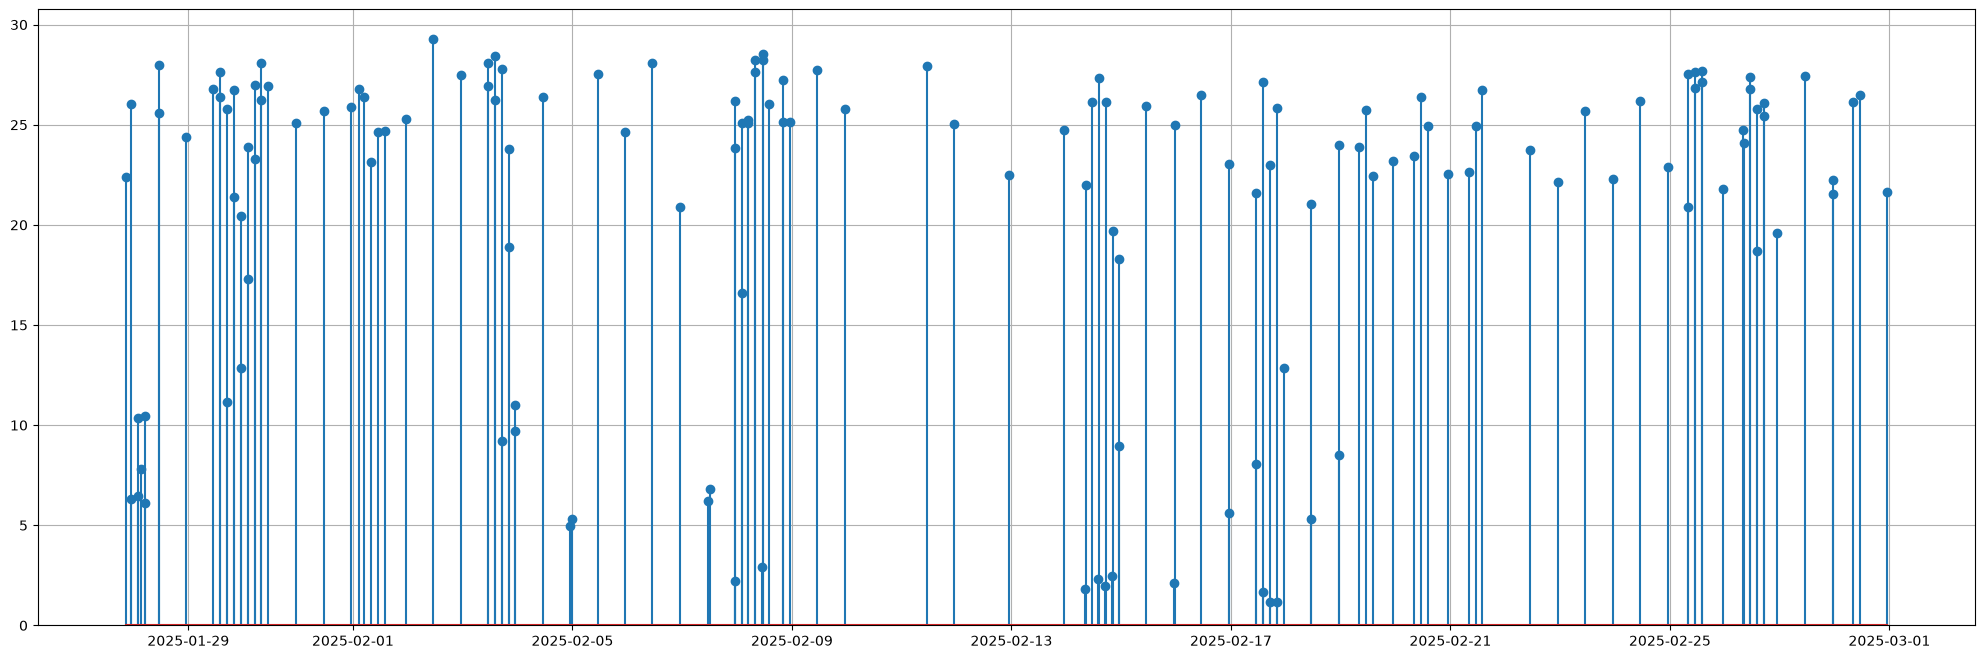

In [ ]:
fig = plt.figure(figsize=(25,8))
ax = fig.subplots(1, 1)

ax.stem(launch_times, max_alts)
ax.set_ylim(0, None)

ax.grid()




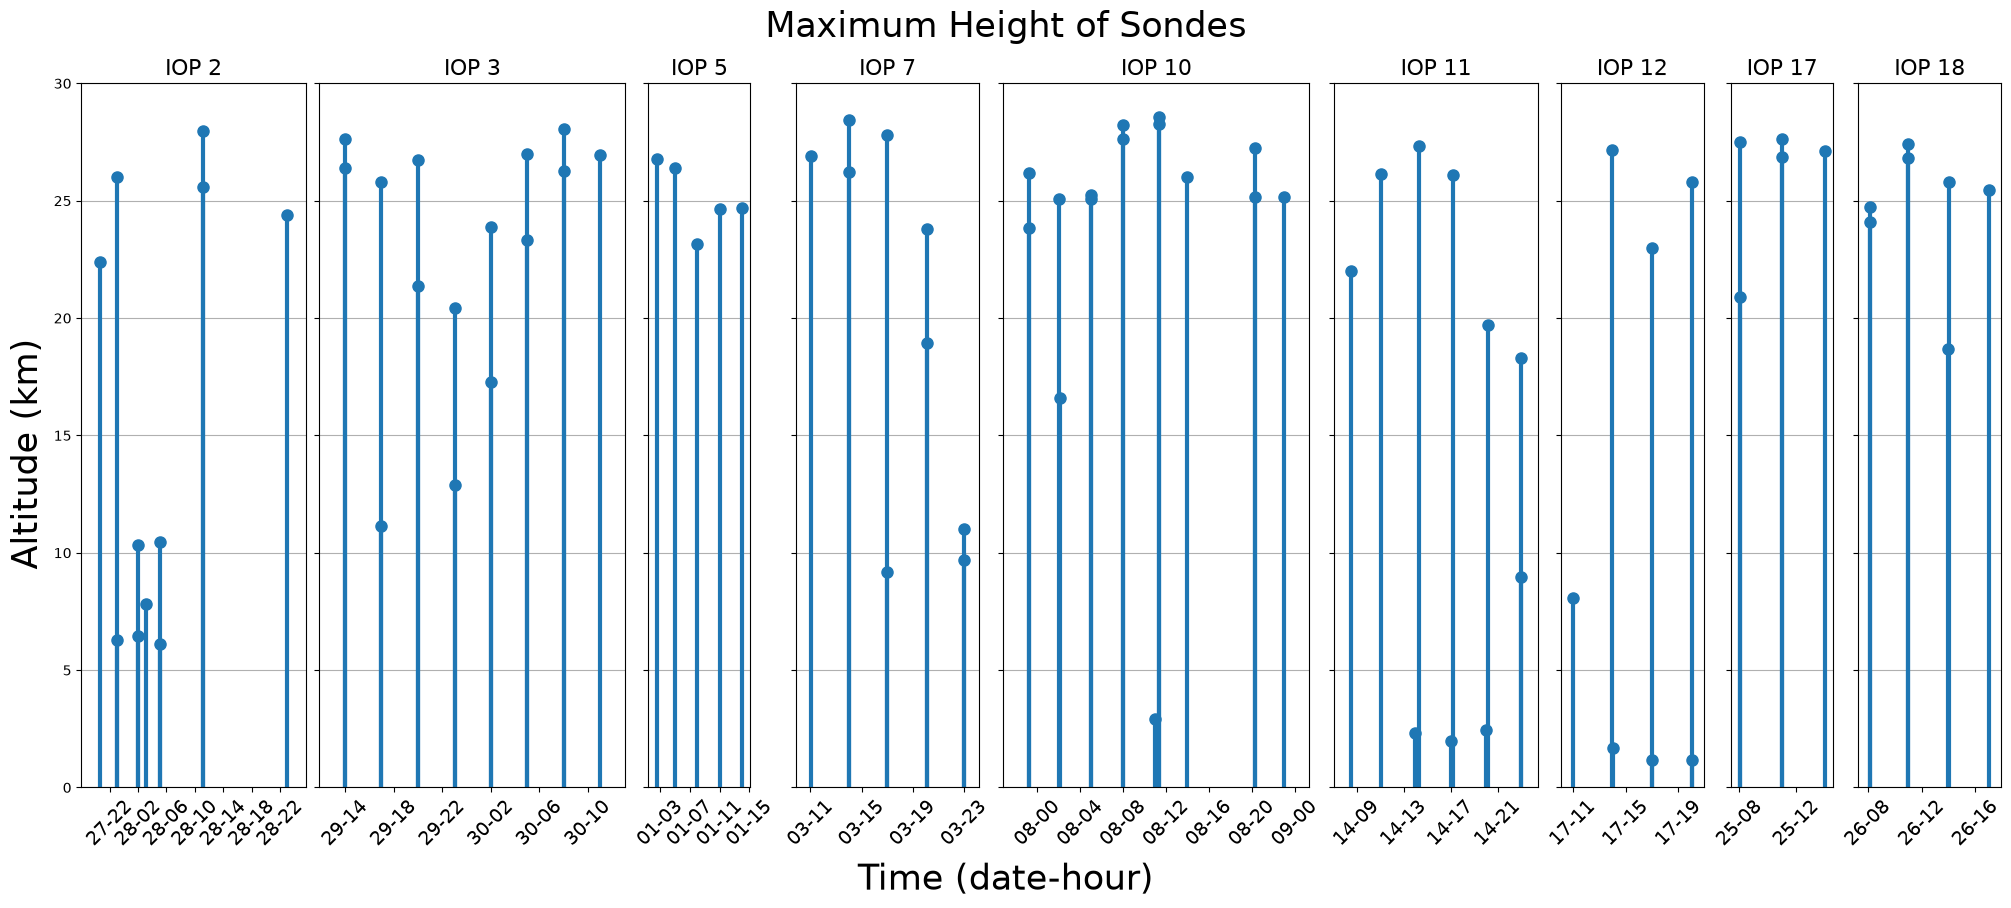

In [33]:
fig = plt.figure(figsize=(20, 8), layout="constrained")
axes = fig.subplots(1, len(iop_windows), sharey=True, gridspec_kw={"width_ratios":iop_width})

for ax, (start, end), label in zip(axes, iop_windows, iop_tick_labels):
    markerline, stemlines, baseline = ax.stem(launch_times[start:end], max_alts[start:end])

    plt.setp(stemlines, linewidth=3)
    plt.setp(markerline, markersize=8)
    plt.setp(baseline, linewidth=0)

    ax.set_ylim(0, 30)
    ax.set_title(f"IOP {label}", fontsize=16)

    #ax.set_xlabel(f"{launch_times[start].strftime("%m-%d")}")
    ax.margins(x=0.1)
    #ax.set_xlim(launch_times[start] - timedelta(hours=1), launch_times[end] + timedelta(hours=1))
    ax.grid(False, axis="x")
    ax.grid(True, axis="y")

# Set up the tick locations here
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%H"))
    locator = mdates.HourLocator(interval=4)
    ax.xaxis.set_major_locator(locator)
    ax.tick_params(axis="x", labelrotation=45, labelsize=14)

fig.suptitle("Maximum Height of Sondes", y=1.055, fontsize=25)
fig.supylabel("Altitude (km)", fontsize=25)
fig.supxlabel("Time (date-hour)", y=-0.055, fontsize=25)

fig.savefig("max_height_sondes.png", dpi=1000, bbox_inches="tight")



In [37]:
50/4000

0.0125